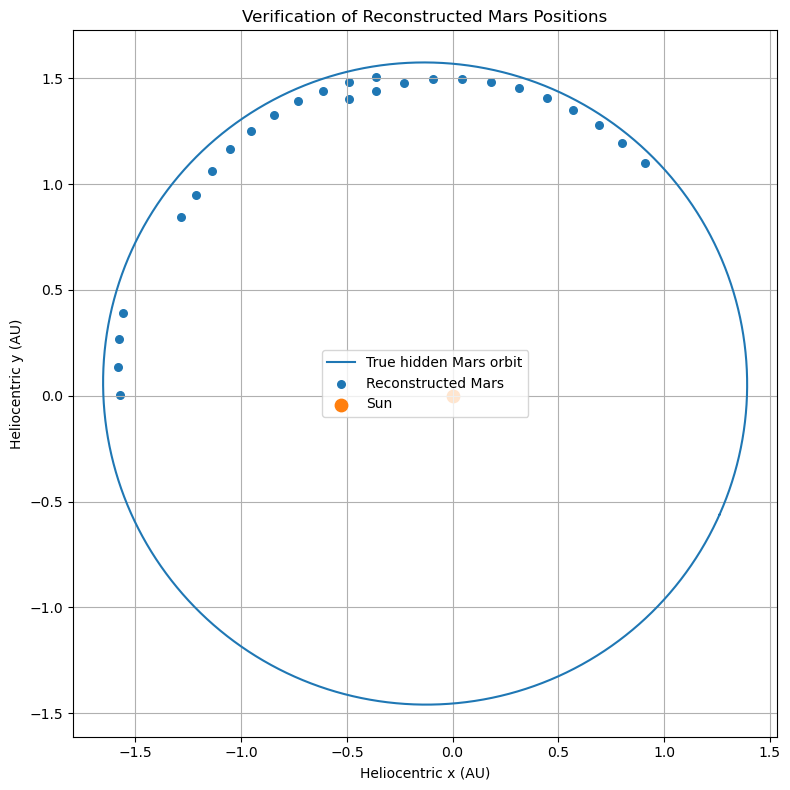

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# Hidden Mars parameters
# VERIFICATION ONLY
# ============================================================

MARS_A = 1.52366231
MARS_E = 0.09341233

MARS_VARPI = math.radians(
    336.04084
)


def true_mars_orbit(
    n=3000
):

    E = np.linspace(
        0,
        2 * np.pi,
        n
    )

    x = MARS_A * (
        np.cos(E)
        - MARS_E
    )

    y = (
        MARS_A
        * np.sqrt(
            1 - MARS_E**2
        )
        * np.sin(E)
    )

    c = np.cos(
        MARS_VARPI
    )

    s = np.sin(
        MARS_VARPI
    )

    xr = (
        c * x
        - s * y
    )

    yr = (
        s * x
        + c * y
    )

    return xr, yr


# ============================================================
# Load reconstructed points
# ============================================================

df = pd.read_csv(
    "mars_reconstructed_1arcmin.csv"
)

true_x, true_y = (
    true_mars_orbit()
)


# ============================================================
# Plot
# ============================================================

plt.figure(
    figsize=(8, 8)
)

plt.plot(
    true_x,
    true_y,
    label="True hidden Mars orbit"
)

plt.scatter(
    df["x_AU"],
    df["y_AU"],
    s=30,
    label="Reconstructed Mars"
)

plt.scatter(
    [0],
    [0],
    s=80,
    label="Sun"
)

plt.xlabel(
    "Heliocentric x (AU)"
)

plt.ylabel(
    "Heliocentric y (AU)"
)

plt.title(
    "Verification of Reconstructed Mars Positions"
)

plt.axis(
    "equal"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()

plt.show()